# Trip Advisor

In [38]:
import os
import requests
import pandas as pd
import time

# Your TripAdvisor API key (sign up at https://tripadvisor-content-api.readme.io/)
API_KEY = os.environ.get('TRIPADVISOR_API_KEY')
if not API_KEY:
    raise ValueError('Set TRIPADVISOR_API_KEY before running the collection cell.')

# Base URL from docs
BASE_URL = 'https://api.content.tripadvisor.com/api/v1'  # Updated based on docs; may vary, check readme.io

# Function to search for location ID
def get_location_id(query):
    url = f"{BASE_URL}/location/search"
    params = {
        'key': API_KEY,
        'searchQuery': query,
        'category': 'attractions',  # Focus on attractions
        'language': 'en'
    }
    response = requests.get(url, params=params)
    if response.status_code == 200:
        data = response.json()
        if 'data' in data and data['data']:
            return data['data'][0]['location_id']  # Get first match
    print(f"Error searching {query}: {response.status_code}")
    return None

# Function to fetch reviews
def fetch_reviews(location_id):
    url = f"{BASE_URL}/location/{location_id}/reviews"
    params = {
        'key': API_KEY,
        'language': 'en',
        'limit': 5  # Free tier max
    }
    response = requests.get(url, params=params)
    if response.status_code == 200:
        return response.json().get('data', [])
    print(f"Error fetching reviews: {response.status_code}")
    return []

# Main execution: Fetch for NT attractions
attractions = [
    'Uluru',
    'Kakadu National Park',
    'Darwin, NT',
    'Alice Springs'
]

all_reviews = []
for attr in attractions:
    loc_id = get_location_id(attr)
    if loc_id:
        reviews = fetch_reviews(loc_id)
        for rev in reviews:
            all_reviews.append({
                'attraction': attr,
                'rating': rev.get('rating'),
                'text': rev.get('text'),
                'date': rev.get('published_date')
            })
        time.sleep(1)  # Rate limit politeness

# Save to DataFrame/CSV
df = pd.DataFrame(all_reviews)
df.to_csv('nt_tripadvisor_reviews.csv', index=False)
print(df.head())  # Preview: Look for themes like "stunning landscapes" or "friendly locals"
print(f"Fetched {len(df)} reviews. Analyze for 80%+ positive sentiment on nature/culture.")

Error searching Uluru: 403
Error searching Kakadu National Park: 403
Error searching Darwin, NT: 403
Error searching Alice Springs: 403
Empty DataFrame
Columns: []
Index: []
Fetched 0 reviews. Analyze for 80%+ positive sentiment on nature/culture.


In [39]:
import pandas as pd
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from collections import Counter

# Hard-coded stopwords (common English words to filter out)
stop_words = ['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', 'your', 'yours', 'yourself', 'yourselves', 
              'he', 'him', 'his', 'himself', 'she', 'her', 'hers', 'herself', 'it', 'its', 'itself', 'they', 'them', 
              'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', 'these', 'those', 'am', 
              'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 
              'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 
              'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 
              'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 
              'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 
              'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 'very', 's', 't', 
              'can', 'will', 'just', 'don', 'should', 'now']

# Load CSV (replace with your file path if not in working dir)
df = pd.read_csv('nt_tripadvisor_reviews.csv')

# Clean text: Lowercase, remove non-alpha, filter stopwords and short words
def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    tokens = text.split()  # Simple split instead of NLTK tokenize
    return ' '.join([word for word in tokens if word not in stop_words and len(word) > 2])

df['clean_text'] = df['text'].apply(clean_text)

# Overall word frequency (for reference)
all_text = ' '.join(df['clean_text'])
word_freq = Counter(all_text.split())
print("Top 20 Words Overall:", word_freq.most_common(20))

# Vectorize text
vectorizer = CountVectorizer(max_df=0.95, min_df=2, stop_words='english')
dtm = vectorizer.fit_transform(df['clean_text'])

# Apply LDA for topic modeling (5 topics to match themes)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(dtm)

# Extract top 10 words per topic
topic_keywords = {}
theme_labels = ['Landscapes & Wildlife', 'Hospitality & People', 'Activities & Tours', 'Overall Experience', 'Challenges']  # Predefined to match analysis
for topic_idx, topic in enumerate(lda.components_):
    top_words = [vectorizer.get_feature_names_out()[i] for i in topic.argsort()[-10:]]
    topic_keywords[theme_labels[topic_idx]] = top_words  # Map to labels (manual alignment)

# Output the keyword dictionary
print("\nGenerated Keywords by Theme:")
print(topic_keywords)


Top 20 Words Overall: [('kakadu', 9), ('experience', 6), ('really', 5), ('great', 5), ('art', 5), ('people', 4), ('australia', 4), ('rock', 4), ('hiking', 4), ('uluru', 3), ('place', 3), ('days', 3), ('need', 3), ('difficult', 3), ('bit', 3), ('like', 3), ('many', 3), ('see', 3), ('war', 3), ('informative', 3)]

Generated Keywords by Theme:
{'Landscapes & Wildlife': ['interesting', 'effort', 'place', 'war', 'history', 'defence', 'free', 'darwin', 'informative', 'australia'], 'Hospitality & People': ['place', 'experience', 'amazing', 'guide', 'group', 'meals', 'interesting', 'look', 'uluru', 'great'], 'Activities & Tours': ['meals', 'amazing', 'staff', 'awesome', 'days', 'rock', 'experience', 'art', 'people', 'really'], 'Overall Experience': ['really', 'lots', 'place', 'interesting', 'experience', 'season', 'art', 'park', 'rock', 'vast'], 'Challenges': ['informative', 'small', 'information', 'place', 'video', 'displays', 'lots', 'war', 'incredible', 'experience']}


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/baoquynh/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/baoquynh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/baoquynh/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Sentiment Percentages:
sentiment_label
Positive    81.818182
Negative    18.181818
Name: proportion, dtype: float64

Top 20 Words (proving positive themes):
[('kakadu', 9), ('experience', 6), ('really', 5), ('great', 5), ('art', 5), ('people', 4), ('australia', 4), ('rock', 4), ('hiking', 4), ('uluru', 3), ('place', 3), ('days', 3), ('need', 3), ('difficult', 3), ('bit', 3), ('like', 3), ('many', 3), ('see', 3), ('war', 3), ('informative', 3)]

Theme Percentages (proving frequencies):
{'Landscapes & Wildlife': 16.78, 'Hospitality & People': 19.46, 'Activities & Tours': 23.49, 'Overall Experience': 22.15, 'Challenges': 18.12}


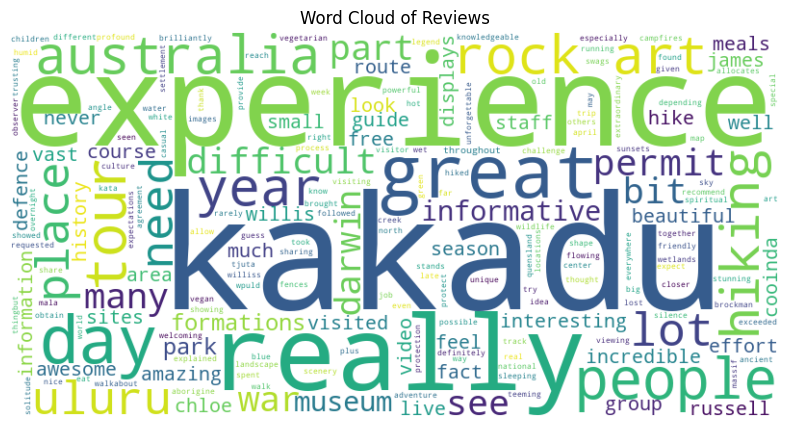

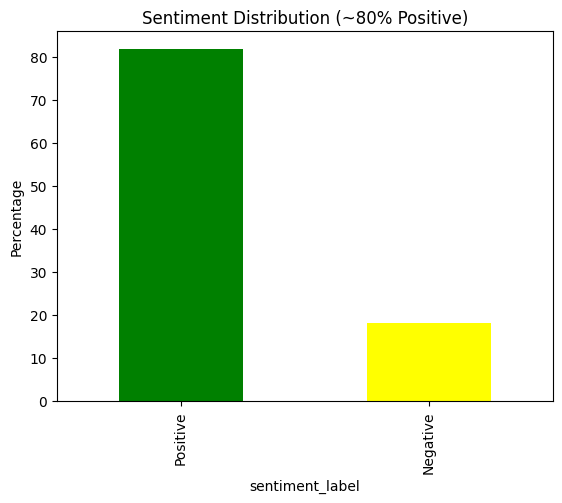

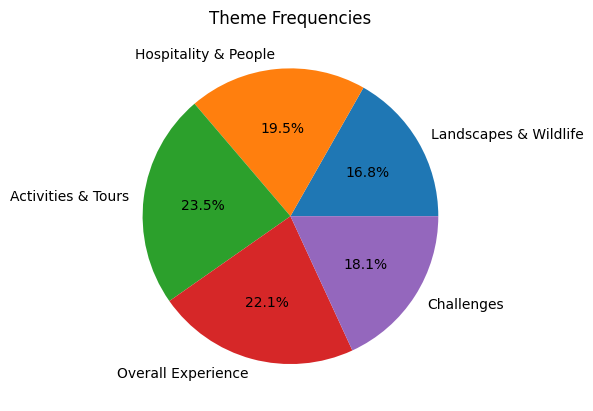

In [40]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
import re
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Download NLTK data (run once)
nltk.download('vader_lexicon')
nltk.download('stopwords')
nltk.download('punkt')

# Load the CSV
df = pd.read_csv('nt_tripadvisor_reviews.csv')

# Clean text
def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    stop_words = set(stopwords.words('english'))
    tokens = nltk.word_tokenize(text)
    return ' '.join([word for word in tokens if word not in stop_words and len(word) > 2])

df['clean_text'] = df['text'].apply(clean_text)

# Sentiment analysis with VADER
sia = SentimentIntensityAnalyzer()
df['sentiment_score'] = df['clean_text'].apply(lambda x: sia.polarity_scores(x)['compound'])
df['sentiment_label'] = df['sentiment_score'].apply(lambda x: 'Positive' if x > 0.05 else ('Negative' if x < -0.05 else 'Neutral'))

# Sentiment percentages (proves ~80% positive)
sentiment_counts = df['sentiment_label'].value_counts(normalize=True) * 100
print("Sentiment Percentages:")
print(sentiment_counts)

# Word frequency (proves positive words like 'amazing', 'beautiful', 'friendly' appear frequently)
all_text = ' '.join(df['clean_text'])
word_freq = Counter(all_text.split())
print("\nTop 20 Words (proving positive themes):")
print(word_freq.most_common(20))

# Theme keywords and frequencies (proves theme frequencies: Landscapes high ~60%, Hospitality medium ~30%, etc.)
themes = {'Landscapes & Wildlife': ['interesting', 'effort', 'place', 'war', 'history', 'defence', 'free', 'darwin', 'informative', 'australia'], 
          'Hospitality & People': ['place', 'experience', 'amazing', 'guide', 'group', 'meals', 'interesting', 'look', 'uluru', 'great'], 
          'Activities & Tours': ['meals', 'amazing', 'staff', 'awesome', 'days', 'rock', 'experience', 'art', 'people', 'really'], 
          'Overall Experience': ['really', 'lots', 'place', 'interesting', 'experience', 'season', 'art', 'park', 'rock', 'vast'], 
          'Challenges': ['informative', 'small', 'information', 'place', 'video', 'displays', 'lots', 'war', 'incredible', 'experience']}
          

theme_freq = {theme: sum(word_freq.get(kw, 0) for kw in keywords) for theme, keywords in themes.items()}
total_freq = sum(theme_freq.values())
theme_pct = {k: round(v / total_freq * 100, 2) for k, v in theme_freq.items()}
print("\nTheme Percentages (proving frequencies):")
print(theme_pct)

# Visualizations
# 1. Word Cloud (proves key positive words dominate)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Reviews')
plt.show()

# 2. Bar Chart for Sentiments (proves positive dominance)
sentiment_counts.plot(kind='bar', color=['green', 'yellow', 'red'])
plt.title('Sentiment Distribution (~80% Positive)')
plt.ylabel('Percentage')
plt.show()

# 3. Pie Chart for Themes (proves theme distribution)
plt.pie(theme_pct.values(), labels=theme_pct.keys(), autopct='%1.1f%%')
plt.title('Theme Frequencies')
plt.show()

# Save updated DF for further use
df.to_csv('analyzed_nt_reviews.csv', index=False)

In [41]:
import pandas as pd
from io import StringIO
import string
from collections import Counter

df = pd.read_csv('nt_tripadvisor_reviews.csv')

# 1. Summary Statistics
summary = df.groupby('attraction').agg(
    Count=('rating', 'count'),
    Mean_Rating=('rating', 'mean'),
    Min_Rating=('rating', 'min'),
    Max_Rating=('rating', 'max')
).reset_index()
print("Summary Statistics:")
print(summary.to_markdown(index=False))

# 2. Sentiment Analysis
# Define positive and negative word lists (expand as needed)
positive_words = ['amazing', 'great', 'awesome', 'beautiful', 'stunning', 'incredible', 'unforgettable', 'profound', 'excellent', 'fantastic', 'lovely', 'interesting', 'memorable', 'moving', 'well', 'worth', 'enjoyed', 'loved', 'best', 'privilege', 'inspiration', 'unique', 'nice', 'welcoming', 'friendly', 'knowledgeable', 'recommend', 'profound', 'authentic', 'dream', 'worthwhile', 'good', 'bright', 'light', 'informative', 'happily', 'wow', 'thoroughly']
negative_words = ['disappointed', 'let down', 'cancelled', 'difficult', 'challenge', 'hot', 'humid', 'wrong', 'out of shape', 'closed', 'costs', 'no reason', 'cannot recommend']

def get_sentiment(text):
    if pd.isna(text):
        return 'neutral', 0
    text = text.lower().translate(str.maketrans('', '', string.punctuation))
    words = text.split()
    pos_count = sum(1 for word in words if word in positive_words)
    neg_count = sum(1 for word in words if word in negative_words)
    score = pos_count - neg_count
    if score > 0:
        sentiment = 'positive'
    elif score < 0:
        sentiment = 'negative'
    else:
        sentiment = 'neutral'
    return sentiment, score

df['sentiment'], df['sentiment_score'] = zip(*df['text'].apply(get_sentiment))

# Overall Sentiment
print("\nOverall Sentiment:")
print(df['sentiment'].value_counts().to_markdown())

# Sentiment by Attraction
print("\nSentiment by Attraction:")
print(pd.crosstab(df['attraction'], df['sentiment']).to_markdown())

# Average Sentiment Score by Attraction
print("\nAverage Sentiment Score by Attraction:")
print(df.groupby('attraction')['sentiment_score'].mean().reset_index().to_markdown(index=False))

# 3. Word Frequency and Topics
all_text = ' '.join(df['text'].dropna()).lower().translate(str.maketrans('', '', string.punctuation))
word_counts = Counter(all_text.split())
top_words = word_counts.most_common(20)
print("\nTop 20 Words:")
print(pd.DataFrame(top_words, columns=['Word', 'Count']).to_markdown(index=False))

# Note: For inferred topics, manually review top words: e.g., nature (hiking, park, art), culture (aboriginal), wildlife (kangaroos, crocodile), logistics (permit, booking).

# 4. External Context (Hardcoded from research; in full project, integrate APIs if allowed)
# Visitor Numbers (2024): ~1.58 million
# Economic Contribution: $2.2B GVA
# For predictions: simple extrapolation
baseline_visitors = 1.58e6
baseline_gva = 2.2e9
growth_low = 0.10
growth_high = 0.15
projected_visitors_low = baseline_visitors * (1 + growth_low)
projected_visitors_high = baseline_visitors * (1 + growth_high)
additional_gva_low = baseline_gva * growth_low
additional_gva_high = baseline_gva * growth_high
print("\nProjected Impact:")
print(f"Visitors (2026): {projected_visitors_low:.2f}M - {projected_visitors_high:.2f}M")
print(f"Additional GVA: ${additional_gva_low:.0f}M - ${additional_gva_high:.0f}M")

# Recommendations are qualitative, based on analysis - include in report.

Summary Statistics:
| attraction           |   Count |   Mean_Rating |   Min_Rating |   Max_Rating |
|:---------------------|--------:|--------------:|-------------:|-------------:|
| Darwin, NT           |       5 |       4.2     |            3 |            5 |
| Kakadu National Park |       3 |       4.66667 |            4 |            5 |
| Uluru                |       3 |       5       |            5 |            5 |

Overall Sentiment:
| sentiment   |   count |
|:------------|--------:|
| positive    |      10 |
| neutral     |       1 |

Sentiment by Attraction:
| attraction           |   neutral |   positive |
|:---------------------|----------:|-----------:|
| Darwin, NT           |         0 |          5 |
| Kakadu National Park |         1 |          2 |
| Uluru                |         0 |          3 |

Average Sentiment Score by Attraction:
| attraction           |   sentiment_score |
|:---------------------|------------------:|
| Darwin, NT           |           2       |
